In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn.model_selection

from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.base import clone

#GridSearch
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV, ParameterSampler
import optuna

from sklearn.preprocessing import StandardScaler #уточнить
from sklearn.base import BaseEstimator,TransformerMixin
#Metrics
from sklearn.metrics import root_mean_squared_error
from sklearn.utils.validation import check_is_fitted
#Pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
#Models
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor

from sklearn.tree import DecisionTreeRegressor, export_graphviz
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor
from catboost import Pool

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import shap
import graphviz

import joblib

from tqdm.auto import tqdm
from tqdm_joblib import tqdm_joblib

import mlflow
from mlflow import MlflowClient

from loguru import logger

import time
import subprocess
import tempfile
from pathlib import Path
from IPython.display import display
import json

In [131]:
SEED = 42

In [132]:
data = pd.read_csv(r'C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House Prices\data\train.csv')
data_test = pd.read_csv(r'C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House Prices\data\test.csv')

## Mlfow logging

In [133]:
class Mlflow_logger():
    def __init__(self,experiment_name):
        self.uri = "http://127.0.0.1:5000"
        self.experiment_name = experiment_name

    def setup_connection(self):
        subprocess.Popen(["python", "-m", "mlflow", "server", "--port", "5000"])
        time.sleep(3)
        print(f"Start mlflow server at --port 5000")
        mlflow.set_tracking_uri(self.uri)
        mlflow.set_experiment(self.experiment_name)
        print(f"Start tracking experiments at {self.uri}")

    def log_fig(self,fig, parameter, run_id):
        client = MlflowClient()

        client.log_figure(
            run_id=run_id,
            figure=fig,
            artifact_file=f"parameter_analysis/{parameter}.png"
        )

    def log_heatmap(self,fig, parameter_x, parameter_y, run_id):
        client = MlflowClient()

        client.log_figure(
            run_id=run_id,
            figure=fig,
            artifact_file=(
                f"parameter_analysis/"
                f"heatmap_{parameter_x}_{parameter_y}.png"
            )
        )

    def log_shap_plots(self,figures):
        for name, fig in figures.items():
            mlflow.log_figure(fig, f"shap/{name}.png")

In [134]:
mymlfow = Mlflow_logger("House_Prices_Kaggle")
mymlfow.setup_connection()

Start mlflow server at --port 5000
Start tracking experiments at http://127.0.0.1:5000


## Рисовашки

In [135]:
class PlotsDrawings():
    def __init__(self,logger:Mlflow_logger):
        self.logger = logger
    #Отбирает из результатов все значения с целевым, а остальные по указаному фиксу
    def draw_parameter(self,results, parameter, fixed_params, log_mlflow=True, run_id = None):

        my_params = fixed_params.copy()
        param_to_check = parameter
        del my_params[param_to_check]

        data = results.copy()

        for key, value in fixed_params.items():

            if key == parameter:
                continue

            column = f'param_{key}'

            if column not in data.columns:
                continue

            if value is None:  
                mask = data[column].isna()

            else:
                mask = data[column].map(
                    lambda x: (
                        np.array_equal(x, value)
                        if isinstance(x, (list, tuple, np.ndarray))
                        and isinstance(value, (list, tuple, np.ndarray))
                        else False
                        if isinstance(x, (list, tuple, np.ndarray))
                        or isinstance(value, (list, tuple, np.ndarray))
                        else x == value
                    )
                )

            data = data.loc[mask]
        
        fig, ax = plt.subplots(figsize=(16, 8))

        ax.errorbar(
            x=data[f'param_{parameter}'].astype(float),
            y=data['mean_test_score'],
            yerr=data['std_test_score'],
            marker='o'
        )

        ax.set_xlabel(parameter)
        ax.set_ylabel('CV accuracy')
        ax.set_title(f'neg_root_mean_squared_error vs {parameter}')
        ax.grid(alpha=0.3)

        self.logger.log_fig(fig,parameter,run_id)
            
        return fig

    def draw_heatmap(self,results,parameter_x,parameter_y,fixed_params,log_mlflow=True,run_id=None):
        
        data = results.copy()

        # 1. Фильтрация по фиксированным гиперпараметрам
        for key, value in fixed_params.items():

            # Параметры осей не фиксируем
            if key in (parameter_x, parameter_y):
                continue

            column = f'param_{key}'

            if column not in data.columns:
                continue

            if value is None:
                mask = data[column].isna()

            elif isinstance(value, (list, tuple, np.ndarray)):
                mask = data[column].map(
                    lambda x: (
                        np.array_equal(x, value)
                        if isinstance(x, (list, tuple, np.ndarray))
                        else False
                    )
                )

            else:
                mask = data[column].map(
                    lambda x: (
                        x == value
                        if not isinstance(x, (list, tuple, np.ndarray))
                        else False
                    )
                )

            # ВАЖНО: фильтрация внутри цикла
            data = data.loc[mask].copy()

        if data.empty:
            raise ValueError(
                "После фильтрации не осталось комбинаций гиперпараметров."
            )

        # 2. Преобразование параметров в числа
        data[parameter_x] = (
            data[f'param_{parameter_x}'].astype(float)
        )

        data[parameter_y] = (
            data[f'param_{parameter_y}'].astype(float)
        )

        # 3. Проверка повторяющихся комбинаций
        duplicates = data.duplicated(
            subset=[parameter_x, parameter_y]
        ).sum()

        if duplicates > 0:
            print(
                f"Найдено {duplicates} повторяющихся комбинаций. "
                "Для них будет рассчитано среднее CV score."
            )

        # 4. Создание матрицы для heatmap
        heatmap_data = data.pivot_table(
            index=parameter_y,
            columns=parameter_x,
            values='mean_test_score',
            aggfunc='mean'
        )

        # 5. Построение графика
        fig, ax = plt.subplots(figsize=(14, 8))

        sns.heatmap(
            -heatmap_data,
            annot=True,
            fmt='.4f',
            cmap='viridis',
            ax=ax
        )

        ax.set_xlabel(parameter_x)
        ax.set_ylabel(parameter_y)
        ax.set_title(
            f'CV RMSE: {parameter_y} vs {parameter_x}'
        )

        # 6. Логирование в MLflow
        self.logger.log_heatmap(fig,parameter_x,parameter_y,run_id)

        return fig

    def create_shap_plots(self, pipelines, mode, X_train, run_id):
        with mlflow.start_run(run_id=run_id):
            shap_frames = []
            base_values = []

            X_background = X_train.sample(
                n=min(100, len(X_train)),
                random_state=42,
            )

            for pipeline in pipelines["estimator"]:
                X_transformed = pipeline[:-1].transform(X_train)
                background = pipeline[:-1].transform(X_background)

                model = pipeline.named_steps["model"]
                if isinstance(X_transformed, pd.DataFrame):
                    # Включая пайплайн без encoder:
                    # FeatureTransformer уже вернул названия столбцов.
                    names = X_transformed.columns.tolist()
                else:
                    names = (
                        pipeline.named_steps["encoder"]
                        .get_feature_names_out()
                        .tolist()
                    )

                match mode:
                    case "catboost" | "lightgbm":
                        explainer = shap.TreeExplainer(
                            model,
                            feature_perturbation="tree_path_dependent",
                        )

                    case "tree":
                        explainer = shap.TreeExplainer(model, background)

                    case "linear":
                        explainer = shap.LinearExplainer(model, background)

                    case _:
                        raise ValueError(f"Неизвестный режим SHAP: {mode!r}")

                explanation = explainer(X_transformed)

                if mode not in ("cat_features", "lightgbm"):
                    explanation = explainer(X_transformed)

                shap_frames.append(
                    pd.DataFrame(explanation.values, columns=names) 
                )
                base_values.append(explanation.base_values)

            # Выравниваем вклады по названиям колонок
            mean_shap = shap_frames[0].copy()

            for frame in shap_frames[1:]:
                mean_shap = mean_shap.add(frame, fill_value=0)

            mean_shap /= len(shap_frames)
            feature_names = mean_shap.columns.tolist()

            shap_values = shap.Explanation(
                values=mean_shap.to_numpy(),
                base_values=np.mean(base_values, axis=0),
                feature_names=feature_names,
            )

            shap_plots = self.draw_shap_plots(
                shap_values,
                sample_idx=0,
                feature_names=feature_names,
            )

        return shap_plots

    def draw_shap_plots(self,shap_values,sample_idx=0,feature_names=None):

        if feature_names is not None:
            shap_values.feature_names = feature_names

        plots = {
            "beeswarm": lambda: shap.plots.beeswarm(shap_values, show=False),
            "waterfall": lambda: shap.plots.waterfall(
                shap_values[sample_idx], show=False
            ),
            "bar": lambda: shap.plots.bar(shap_values, show=False),
        }

        figures = {}

        for name, draw in plots.items():
            plt.figure()
            draw()
            fig = plt.gcf()

            fig.set_size_inches(16, 8)
            fig.subplots_adjust(left=0.35, right=0.95)

            figures[name] = fig
            plt.close(fig)

        self.logger.log_shap_plots(figures)
        return list(figures.values())
            

In [136]:
plot_drawer = PlotsDrawings(mymlfow)

## Split

In [137]:
y_train = np.log1p(data['SalePrice'])
data = data.drop('SalePrice',axis = 1)
X_train, X_holdout, y_train, y_holdout = train_test_split(
    data,
    y_train,
    test_size=0.2,  # 10% данных уйдет в тест, 90% — в train
    random_state=42,  # фиксирует случайность для воспроизводимости
    shuffle=True,  # перемешивать данные перед разделением (по умолчанию True)
)

## Feature Transformer

In [138]:
class FeatureTransformer(TransformerMixin, BaseEstimator):
    cat_cols = [
            "MSSubClass",
            "MSZoning",
            "Alley",
            "LotConfig",
            "LandContour",
            "Neighborhood",
            "BldgType",
            "HouseStyle",
            "RoofStyle",
            "RoofMatl",
            "Exterior1st",
            "Foundation",
            "Heating",
            "Condition1",
            "Condition2",
            "Exterior2nd",
            "GarageType",
            "PavedDrive",
            "Fence",
            "MiscFeature",
            "SaleType",
            "SaleCondition",
            "LotShape",
            "Electrical",
        ]
    def __init__(self,cat_boosting = False):
        self.cat_boosting = cat_boosting
        self.X_cols = [
            "MSSubClass",
            "MSZoning",
            "Alley",
            "LotConfig",
            "LandContour",
            "Neighborhood",
            "BldgType",
            "HouseStyle",
            "RoofStyle",
            "RoofMatl",
            "Exterior1st",
            "Foundation",
            "Heating",
            "Condition1",
            "Condition2",
            "Exterior2nd",
            "GarageType",
            "PavedDrive",
            "Fence",
            "MiscFeature",
            "SaleType",
            "SaleCondition",
            "LotShape",
            "Electrical",
            "FullBath",
            "TotRmsAbvGrd",
            "GarageCars",
            "BedroomAbvGr",
            "KitchenAbvGr",
            "Utilities",
            "OverallQual",
            "OverallCond",
            "ExterCond",
            "BsmtQual",
            "HeatingQC",
            "KitchenQual",
            "GarageFinish",
            "Functional",
            "LandSlope",
            "BsmtExposure",
            "CentralAir",
            "Street",
            "BsmtHalfBath",
            "HalfBath",
            "OpenPorch",
            "EnclosedPorch",
            "3SsnPorch",
            "ScreenPorch",
            "LowQualFin",
            "BsmtFin",
            "LotFrontage",
            "LotFrontage_log",
            "LotArea",
            "LotArea_log",
            "MasVnrArea",
            "MasVnrArea_log",
            "BsmtFinSF1",
            "BsmtFinSF1_log",
            "BsmtUnfSF",
            "BsmtUnfSF_log",
            "TotalBsmtSF",
            "TotalBsmtSF_log",
            "1stFlrSF",
            "1stFlrSF_log",
            "2ndFlrSF",
            "2ndFlrSF_log",
            "GarageArea",
            "GarageArea_log",
            "WoodDeckSF",
            "WoodDeckSF_log",
            "OpenPorchSF",
            "OpenPorchSF_log",
            "MiscVal",
            "MiscVal_log",
            "TotalSqFeet",
            "TotalSqFeet_log",
            "MoSold",
            "YrSold",
            "Age",
            "Age_from_Remod",
            "OverallQual*OverallCond",
            "ExterQual*ExterCond",
            "BsmtFinType1*BsmtFinSF1*BsmtQual",
            "BsmtFinType2*BsmtFinSF2*BsmtQual",
            "OverallBath",
            "PoolOverall",
            "Overall_Fireplaces",
        ]
            
        self.cat_cols = type(self).cat_cols.copy()
        
        self.continuous_cols = [
            "LotFrontage",
            "LotArea",
            "MasVnrArea",
            "BsmtFinSF1",
            "BsmtFinSF2",
            "BsmtUnfSF",
            "TotalBsmtSF",
            "1stFlrSF",
            'OpenPorchSF',
            "2ndFlrSF",
            "LowQualFinSF",
            "GrLivArea",
            "GarageArea",
            "WoodDeckSF",
            "PoolArea",
            "MiscVal",
            'TotalSqFeet'
        ]

        self.ordinal_mapping = {
            "Utilities": {"ELO": 1, "NoSeWa": 2, "NoSewr": 3, "AllPub": 4},
            "LandSlope": {"Sev": 1, "Mod": 2, "Gtl": 3},
            "ExterQual": {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
            "ExterCond": {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
            "HeatingQC": {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
            "KitchenQual": {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
            "Functional": {
                "Sal": 0,
                "Sev": 1,
                "Maj2": 2,
                "Maj1": 3,
                "Mod": 4,
                "Min2": 5,
                "Min1": 6,
                "Typ": 7,
            },
            "GarageFinish": {"NA": 0, "Unf": 1, "RFn": 2, "Fin": 3},
            "GarageQual": {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
            "GarageCond": {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
        }

        self.basement_mapping = {
            "BsmtQual": {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "NA": 0},
            "BsmtCond": {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "NA": 0},
            "BsmtExposure": {"Gd": 4, "Av": 3, "Mn": 2, "No": 1, "NA": 0},
            "BsmtFinType1": {
                "GLQ": 6,
                "ALQ": 5,
                "BLQ": 4,
                "Rec": 3,
                "LwQ": 2,
                "Unf": 1,
                "NA": 0,
            },
            "BsmtFinType2": {
                "GLQ": 6,
                "ALQ": 5,
                "BLQ": 4,
                "Rec": 3,
                "LwQ": 2,
                "Unf": 1,
                "NA": 0,
            },
        }

        self.quality_mapping = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "NA": 0}

        #Statistics
        #LotFrontage
        self.frontage_by_area = None
        self.frontage_global = None

    def fit(self, data, y=None):
        
        if "LotFrontage" in data.columns:
            self.frontage_by_area = data.groupby("Neighborhood")["LotFrontage"].median()
            self.frontage_global = data["LotFrontage"].median()
        if "MSZoning" in data.columns:
            self.mszoning = (data.groupby("Neighborhood")["MSZoning"].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan))
            self.mszoning_global_ = data["MSZoning"].mode().iloc[0]

        #Собираем самые частые значения фичей на трейн
        self.miss_cols = ["Exterior1st","Exterior2nd","SaleType","Utilities","KitchenQual", "Functional"]

        self.fill_modes_ = {
            col: data[col].mode().iloc[0]
            for col in self.miss_cols}
        
        self.is_fitted_ = True
        return self

    def fit_transform(self,data,y=None):
        return self.fit(data, y).transform(data)
    
    def transform(self,data):
        check_is_fitted(self, "is_fitted_")
        data = data.copy()
        if "LotFrontage" in data.columns:
            data["LotFrontage"] = (
                data["LotFrontage"]
                .fillna(data["Neighborhood"].map(self.frontage_by_area))
                .fillna(self.frontage_global)
            )
        data["MSZoning"] = (
            data["MSZoning"]
            .fillna(data["Neighborhood"].map(self.mszoning))
            .fillna(self.mszoning_global_)
            )
        
        data = data.fillna(self.fill_modes_)
        data = self.fill_missing(data)
        data = self.create_features(data)

        empty_colls = []

        for col in data.columns:
            if data[col].isnull().any():
                empty_colls.append(col)
        if len(empty_colls) > 0:
            message = f"Обнаружены колонки с пропусками в test/val: {', '.join(empty_colls)}"
            raise ValueError(message)

        if self.cat_boosting:
            data[self.cat_cols] = data[self.cat_cols].astype('category')

        return data

    def fill_missing(self, data):
        data = data.copy()

        default_na = [
            "Alley",
            "GarageType",
            "GarageFinish",
            "GarageQual",
            "GarageCond",
            "FireplaceQu",
            "PoolQC",
            "MiscFeature",
        ]
        for col in default_na:
            data[col] = data[col].fillna("NA")

        data["Fence"] = data["Fence"].fillna("NoFence")
        data["Electrical"] = data["Electrical"].fillna("SBrkr")

        basement_cols = list(self.basement_mapping)
        has_basement = data[["BsmtQual", "BsmtCond", "BsmtFinType1"]].notna().any(axis=1)
        data.loc[has_basement & data["BsmtExposure"].isna(), "BsmtExposure"] = "No"
        data.loc[has_basement & data["BsmtFinType2"].isna(), "BsmtFinType2"] = "Unf"
        data[basement_cols] = data[basement_cols].fillna("NA")

        #Подумать это проуски в тесте, особенно над последними тремя
        for col in self.miss_cols:
            data[col] = data[col].fillna(value=self.fill_modes_)
        
        zero_cols = [
            "MasVnrArea",
            "BsmtFinSF1",
            "BsmtFinSF2",
            "BsmtUnfSF",
            "TotalBsmtSF",
            "BsmtFullBath",
            "BsmtHalfBath",
            "GarageCars",
            "GarageArea",]
        
        data[zero_cols] = data[zero_cols].fillna(0)

        if "GarageYrBlt" in data.columns:
            data["GarageYrBlt"] = data["GarageYrBlt"].fillna(data["YearBuilt"])

        return data


    def create_features(self,data):
        data = data.copy()

        data["Electrical"] = data["Electrical"].map(
            {
                "Mix": "Other",
                "FuseP": "Fuse",
                "FuseF": "Fuse",
                "FuseA": "Fuse",
                "SBrkr": "CircuitBreaker",
            }
        )

        for col, mapping in {**self.basement_mapping, **self.ordinal_mapping}.items():
            data[col] = data[col].map(mapping)

        data["FireplaceQu"] = data["FireplaceQu"].map(self.quality_mapping)
        data["PoolQC"] = data["PoolQC"].map({"Ex": 5, "Gd": 4, "Fa": 2, "NA": 0})
        data["CentralAir"] = data["CentralAir"].map({"Y": 1, "N": 0})
        data["Street"] = data["Street"].map({"Pave": 1, "Grvl": 0})

        data["Pool"] = (data["PoolArea"] != 0).astype(int)
        data["EnclosedPorch"] = (data["EnclosedPorch"] != 0).astype(int)
        data["3SsnPorch"] = (data["3SsnPorch"] != 0).astype(int)
        data["ScreenPorch"] = (data["ScreenPorch"] != 0).astype(int)
        data["OpenPorch"] = (data["OpenPorchSF"] != 0).astype(int)
        data["LowQualFin"] = (data["LowQualFinSF"] != 0).astype(int)
        data["BsmtFin"] = (data["BsmtFinSF2"] != 0).astype(int)

        data["Age"] = data["YrSold"] - data["YearBuilt"]
        data["Age_from_Remod"] = data["YrSold"] - data["YearRemodAdd"]
        data["TotalSqFeet"] = data["GrLivArea"] + data["TotalBsmtSF"]
        data["OverallQual*OverallCond"] = data["OverallQual"] * data["OverallCond"]
        data["ExterQual*ExterCond"] = data["ExterQual"] * data["ExterCond"]
        data["BsmtFinType1*BsmtFinSF1*BsmtQual"] = (
            data["BsmtFinType1"] * data["BsmtFinSF1"] * data["BsmtQual"]
        )
        data["BsmtFinType2*BsmtFinSF2*BsmtQual"] = (
            data["BsmtFinType2"] * data["BsmtFinSF2"] * data["BsmtQual"]
        )
        data["OverallBath"] = (
            data["FullBath"]
            + data["HalfBath"]
            + data["BsmtFullBath"]
            + data["BsmtHalfBath"]
        )
        for col in ["BsmtHalfBath", "BsmtFullBath", "HalfBath"]:
            data[col] = (data[col] > 0).astype(int)
        
        data["PoolOverall"] = data["PoolQC"] * data["Pool"]
        data["Overall_Fireplaces"] = data["FireplaceQu"] * data["Fireplaces"]

        for feature in self.continuous_cols:
            data[f'{feature}_log'] = np.log1p(data[feature])

        data = data[self.X_cols].copy()
        return data

## Валидация

In [139]:
def search_params(X,y,cv_obj,pipline,parameters,fit_params,n_iter,type_of_search = RandomizedSearchCV,run_name=None):

    if run_name is None:
        run_name = type(pipline.named_steps['model']).__name__
    #Satrt mlfow logging
    with mlflow.start_run(run_name=run_name) as run:
        model_run_id = run.info.run_id
        #Logging input params
        mlflow.log_params({"model_type": run_name,"cv_folds": cv_obj.get_n_splits(),"scoring": "neg_root_mean_squared_error","n_features": X.shape[1],"n_samples": X.shape[0]})
        #Run search
        #Get splits
        splits = list(cv_obj.split(X, y))
        CV_model = type_of_search(pipline,parameters,cv=splits,n_iter=n_iter,scoring='neg_root_mean_squared_error',n_jobs=-1, verbose = 3,refit = False,error_score='raise',random_state=SEED)

        n_candidates = len(ParameterSampler(
            parameters,
            n_iter=n_iter,
            random_state=42,
        ))
        total_fits = n_candidates * len(splits)

        with tqdm_joblib(tqdm(total=total_fits, desc="RandomizedSearchCV")):
            CV_model.fit(X, y,**fit_params)

        #Train best_pipeline on CV
        best_pipeline = clone(pipline).set_params(**CV_model.best_params_)

        results = cross_validate(
            best_pipeline,
            X,
            y,
            cv=splits,
            scoring="neg_root_mean_squared_error",
            return_estimator=True,
            n_jobs=-1,
            error_score="raise",
            params=fit_params
        )

        #Сount OOF metric
        oof_pred = np.full(len(y), np.nan)

        for pipeline, (_, val_idx) in zip(results["estimator"], splits):
            oof_pred[val_idx] = pipeline.predict(X.iloc[val_idx])

        if np.isnan(oof_pred).any():
            raise ValueError("Не для всех объектов получены OOF-предсказания.")
        #считаем OOF RMSE
        oof_rmse = np.sqrt(np.mean((np.asarray(y) - oof_pred) ** 2))
        mlflow.log_metric("oof_rmse", oof_rmse)

        model_ids = []
        #Logging pipelines
        for fold, fitted_pipeline in enumerate(results["estimator"]):
            info = mlflow.sklearn.log_model(
                sk_model=fitted_pipeline,
                name=f"pipeline_fold_{fold}",
                serialization_format="cloudpickle",)
            model_ids.append(info.model_uri)

        results_df = pd.DataFrame(CV_model.cv_results_)

        #Log best resukt in parent Run
        mlflow.log_params(CV_model.best_params_)
        best_idx = CV_model.best_index_

        mlflow.log_metrics({"best_cv_rmse": -CV_model.best_score_,"best_cv_rmse_std": float(results_df.loc[best_idx, "std_test_score"]),"n_candidates": len(results_df)})
        mlflow.set_tag("best_model",type(results["estimator"][0].named_steps["model"]).__name__)

        #Save result table
        mlflow.log_table(results_df,"cv_results.json")
 
        return results,CV_model.best_params_,CV_model.best_score_,oof_rmse,results_df,model_run_id,model_ids


In [140]:
skf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

In [141]:
encoder_transformer = ColumnTransformer(
    transformers=[
        ('one_hot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), FeatureTransformer.cat_cols)
    ],
    remainder='passthrough'
)

In [142]:
X_numeric = X_train.select_dtypes(include='number')

print(np.isinf(X_numeric.to_numpy()).sum())

0


## Baseline

### Linear Regression Lasso

In [143]:
pipe_lasso = Pipeline([
    ('feature_tranform', FeatureTransformer()),
    ('encoder', encoder_transformer),
    ('scaler', StandardScaler()),
    ('model', Lasso())
])
fit_params = {}

In [144]:
# models = [Linear Regression]
param_names_lasso = {
            'model__alpha':np.linspace(0.001,0.01,100),#[np.float64(1.053578947368421)], #np.linspace(0.001,20,20),
            'model__max_iter':[1000],
            'model__random_state':[SEED]}

In [145]:
best_Lasso,best_param,best_scor,oof_rmse,result,lasso_run_id,model_ids  =  search_params(X_train,y_train,skf,pipe_lasso,param_names_lasso,fit_params,n_iter=150)
print(
    f"Лучшие параметры: {best_param}\n"
    f"CV RMSE: {-best_scor:.5f}\n"
    f"OOF RMSE: {oof_rmse:.5f}"
)
print(model_ids)

RandomizedSearchCV:   0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 100 is smaller than n_iter=150. Running 100 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 100 candidates, totalling 500 fits


2026/10/26 16:03:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/26 16:03:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/26 16:04:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mec

🏃 View run Lasso at: http://127.0.0.1:5000/#/experiments/1/runs/3c463d4853f14786aec24a34a88581ce
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Лучшие параметры: {'model__random_state': 42, 'model__max_iter': 1000, 'model__alpha': np.float64(0.0037272727272727275)}
CV RMSE: 0.13434
OOF RMSE: 0.13729
['models:/m-b7afe5eb0e9e479a8841f2643fbcd783', 'models:/m-1361a10156f1479cadf471cc9a9ebaac', 'models:/m-4facc80ee9e5433c98278f2941228829', 'models:/m-bc2368fb663f47ccb9d31201652f4d7f', 'models:/m-d5d5bc63f49c45658aab8e6fce9a04ec']


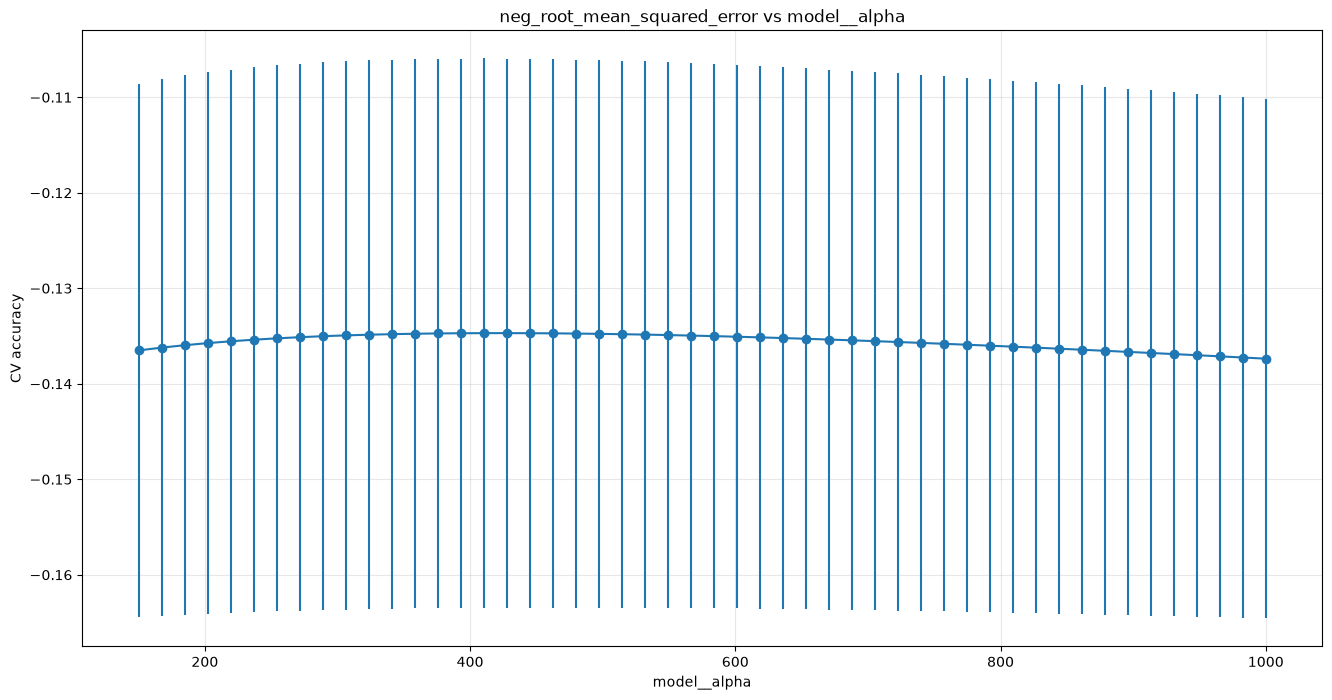

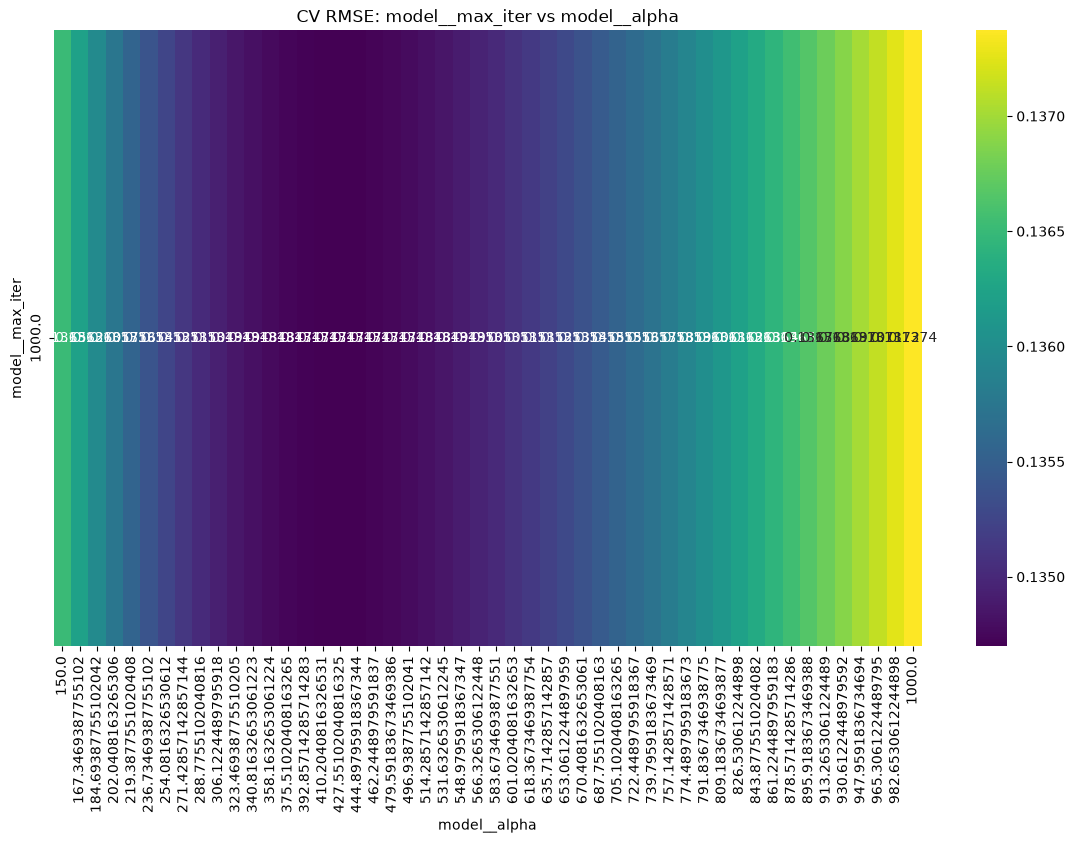

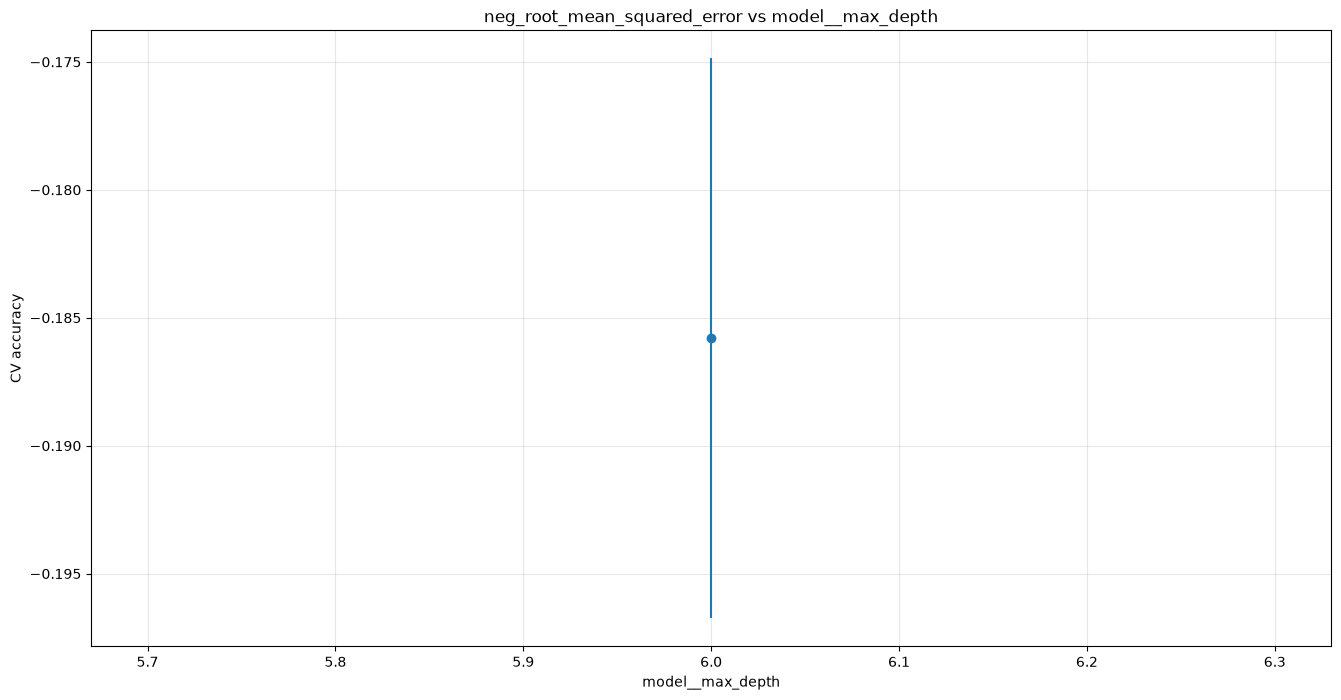

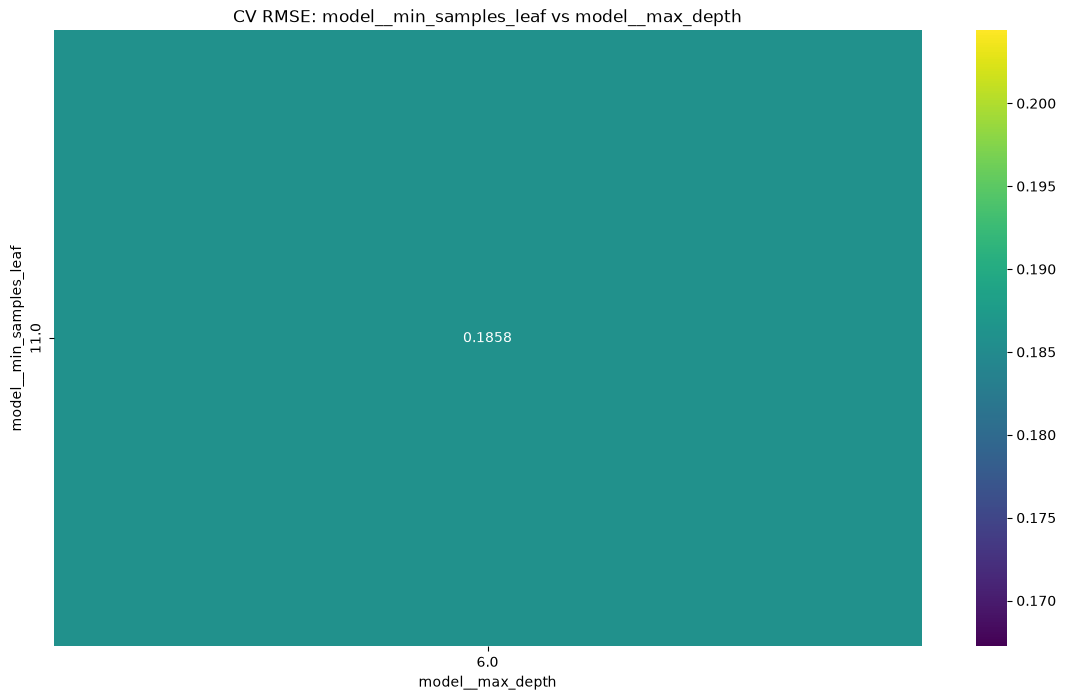

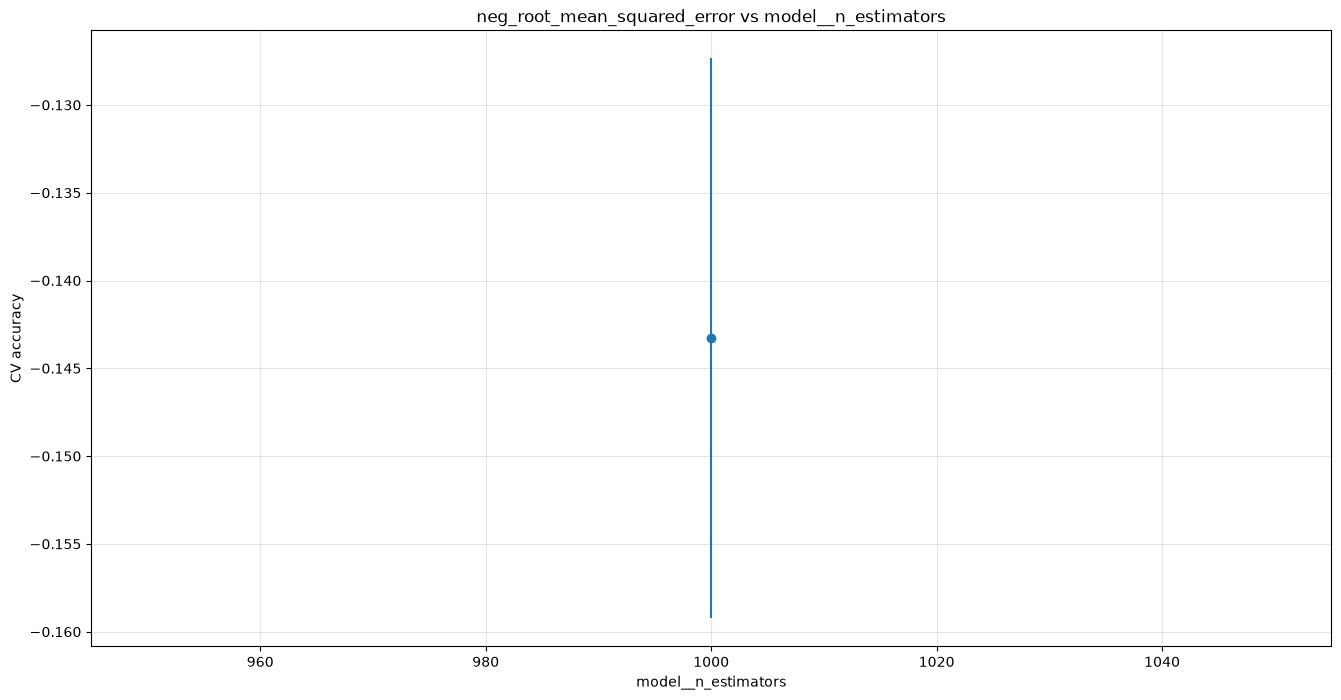

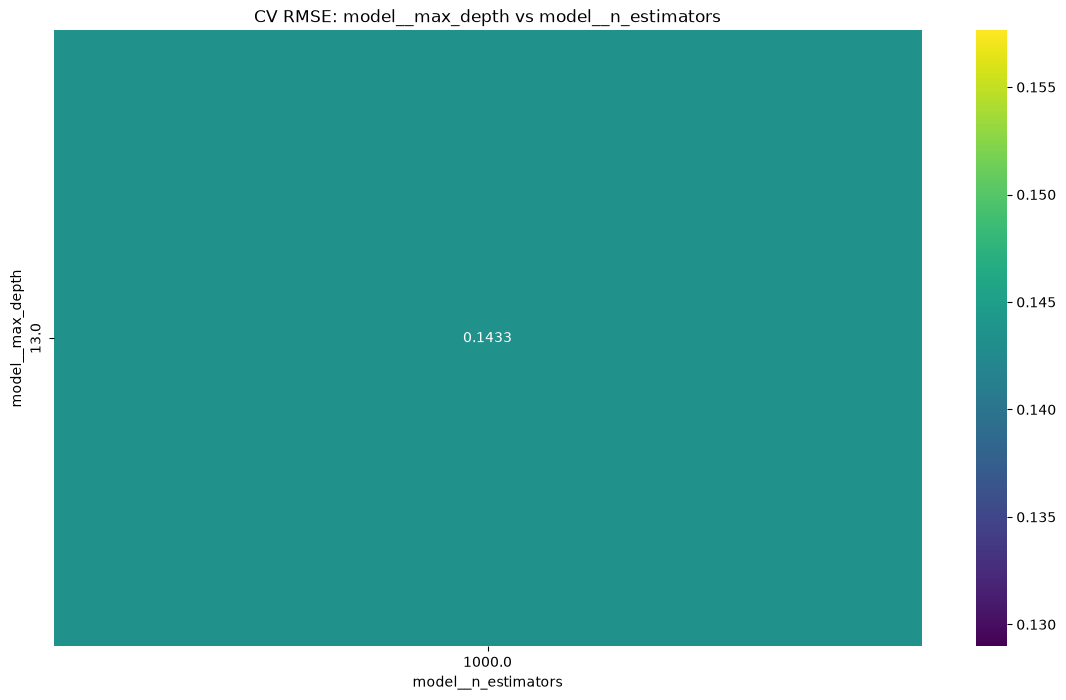

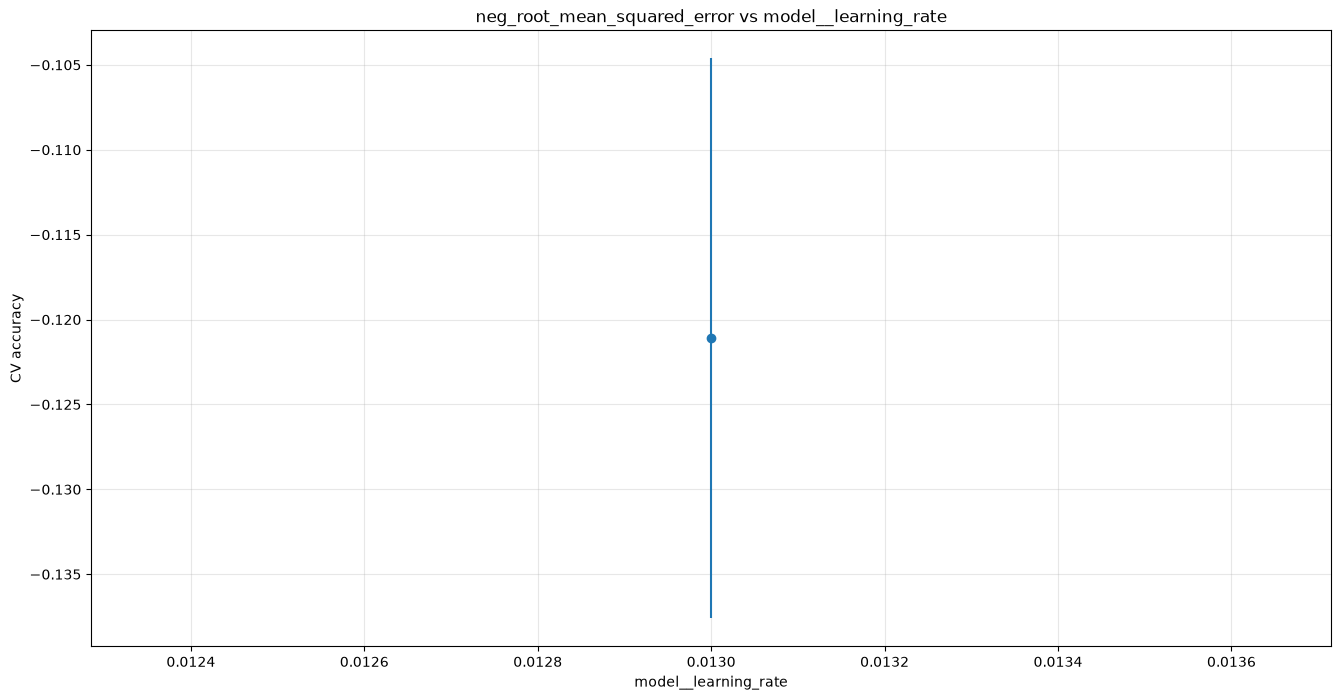

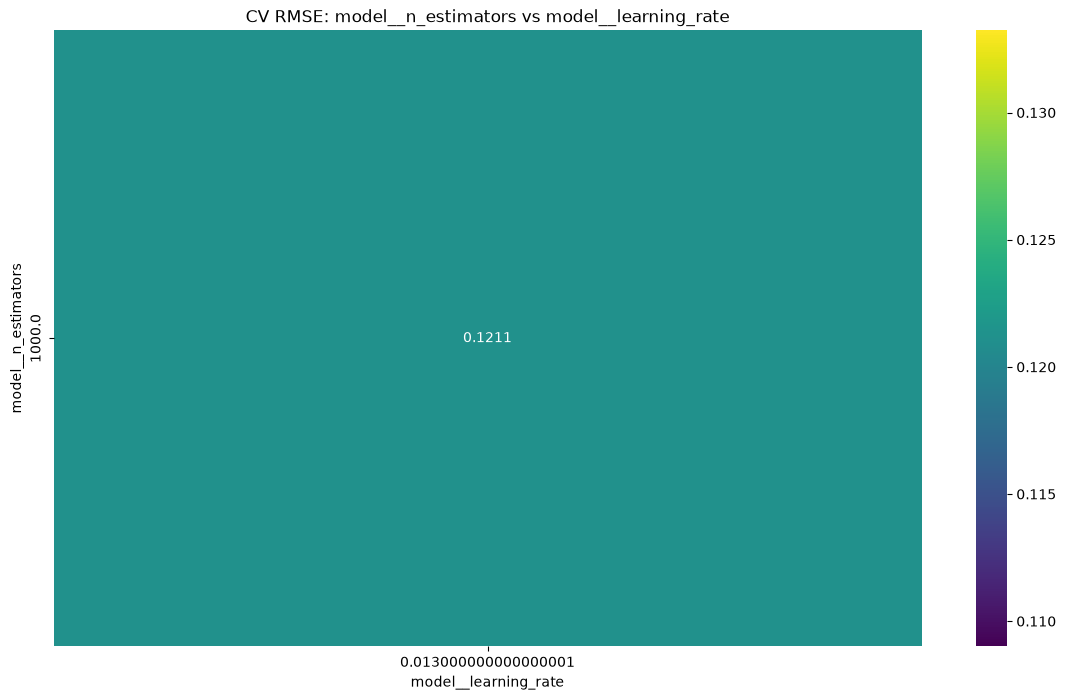

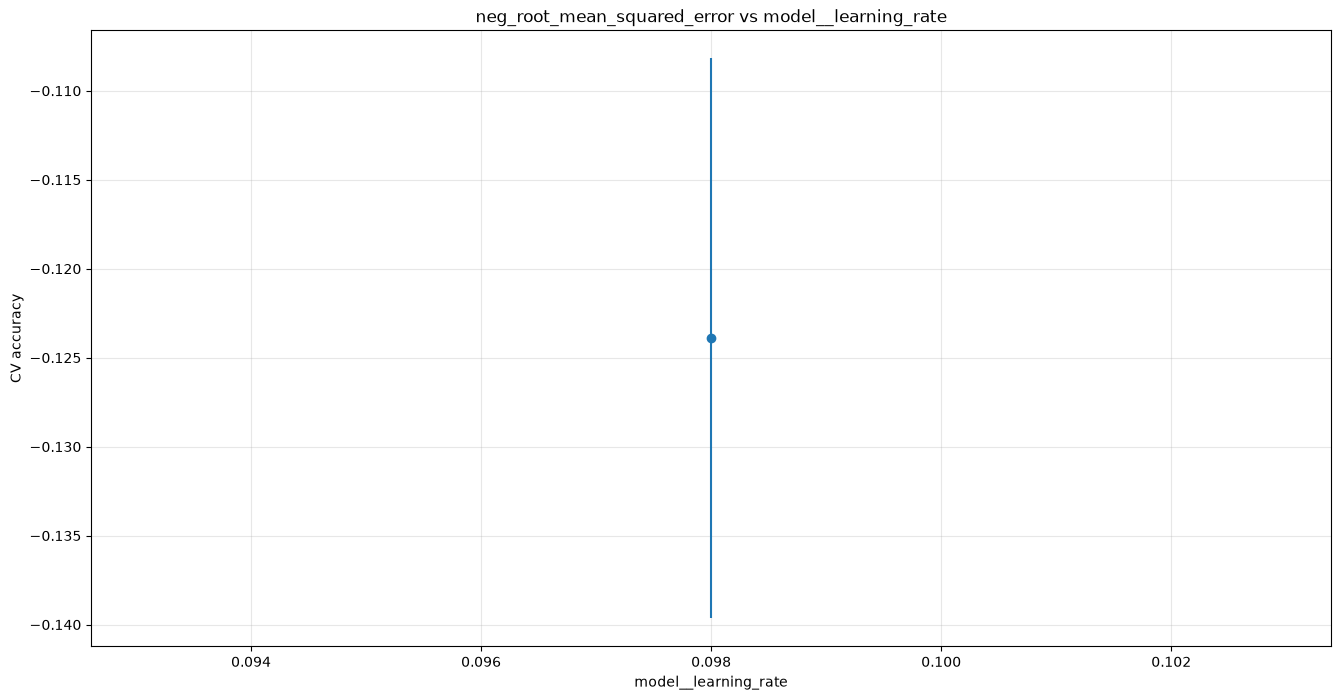

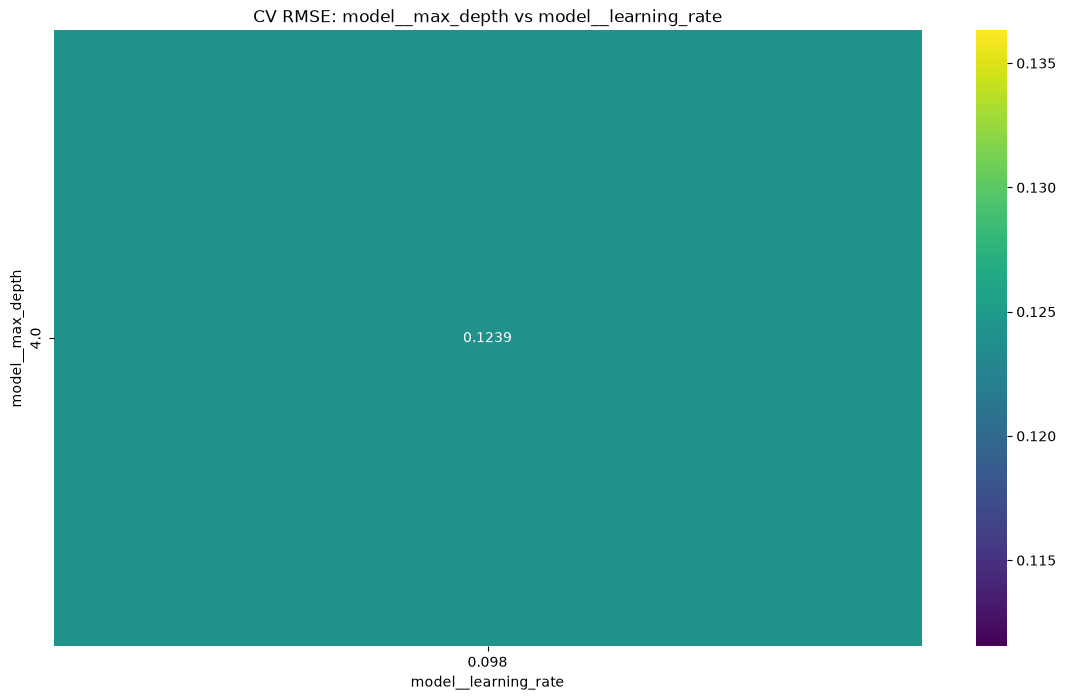

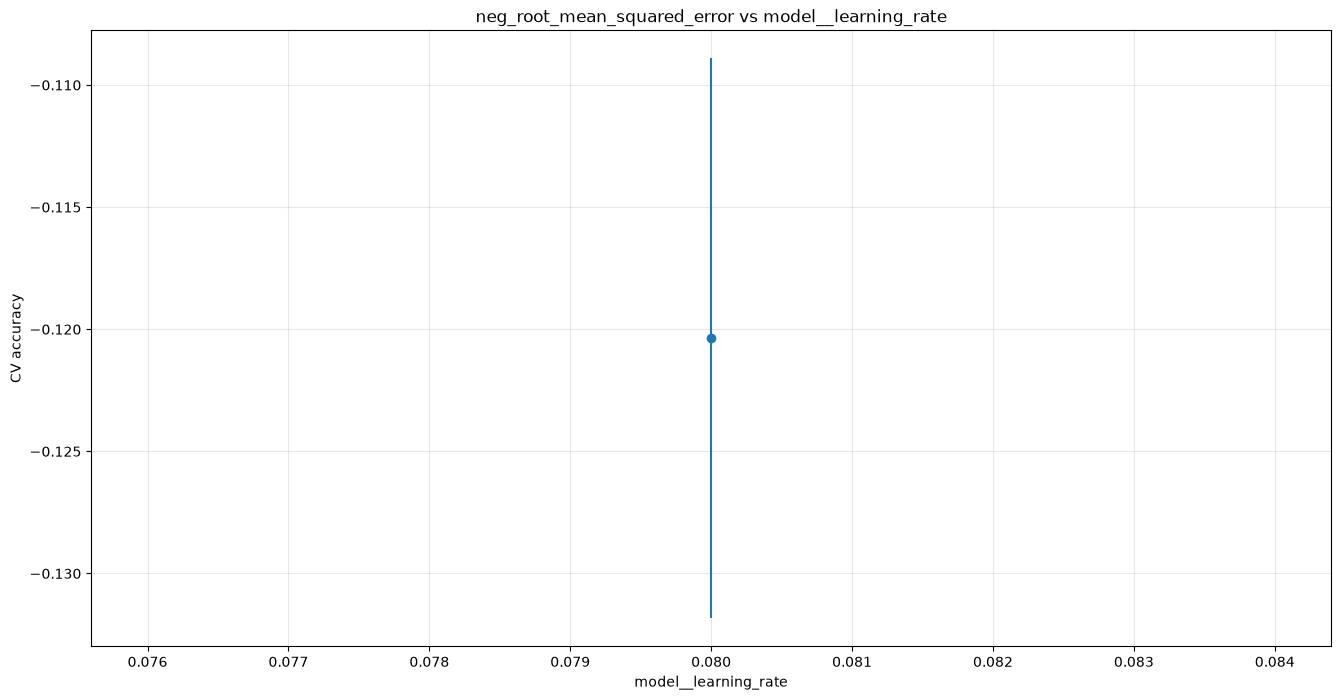

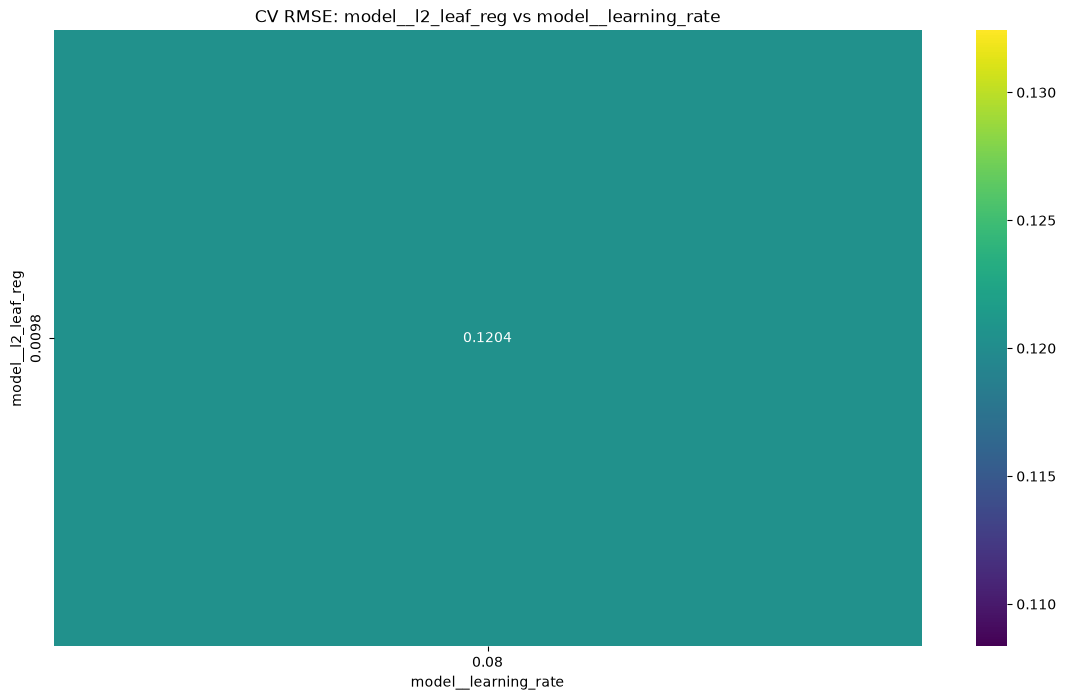

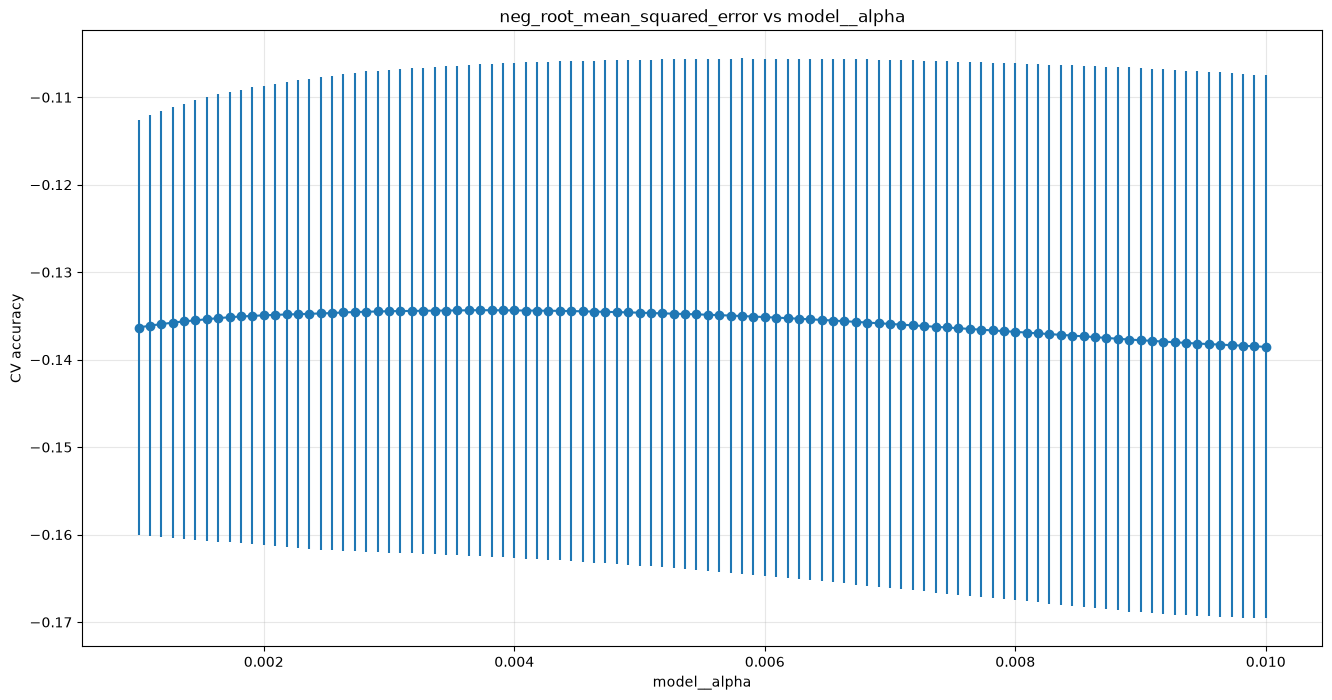

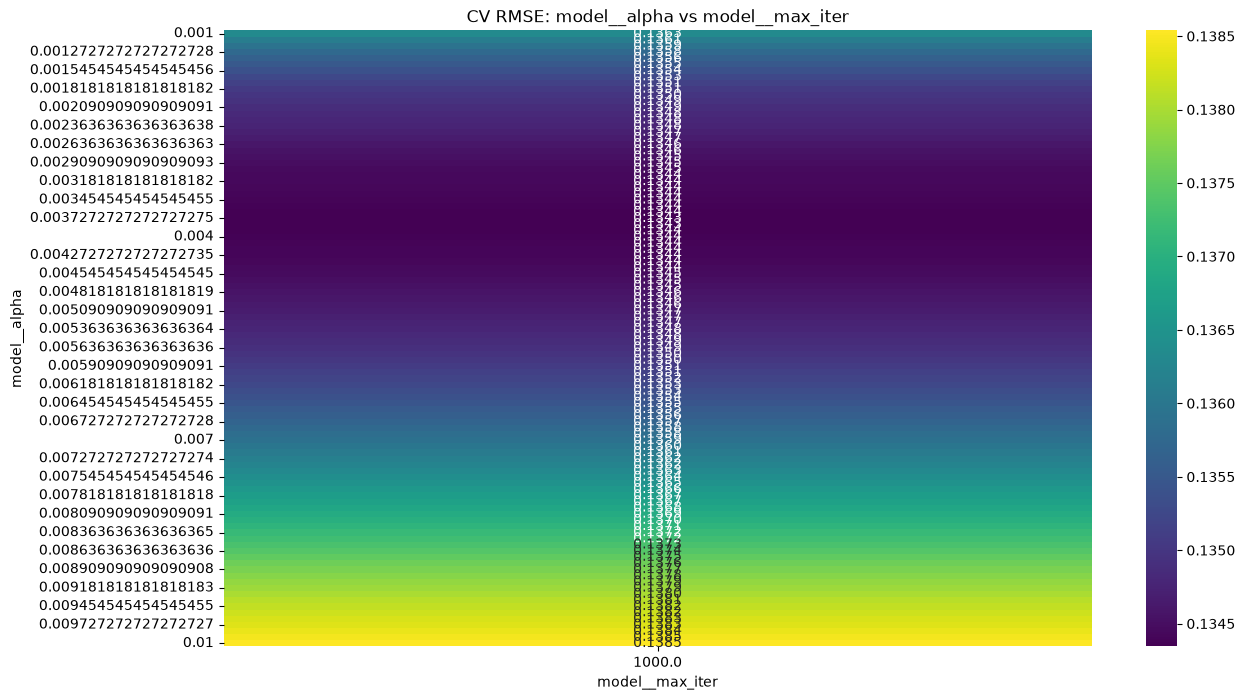

🏃 View run Lasso at: http://127.0.0.1:5000/#/experiments/1/runs/3c463d4853f14786aec24a34a88581ce
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


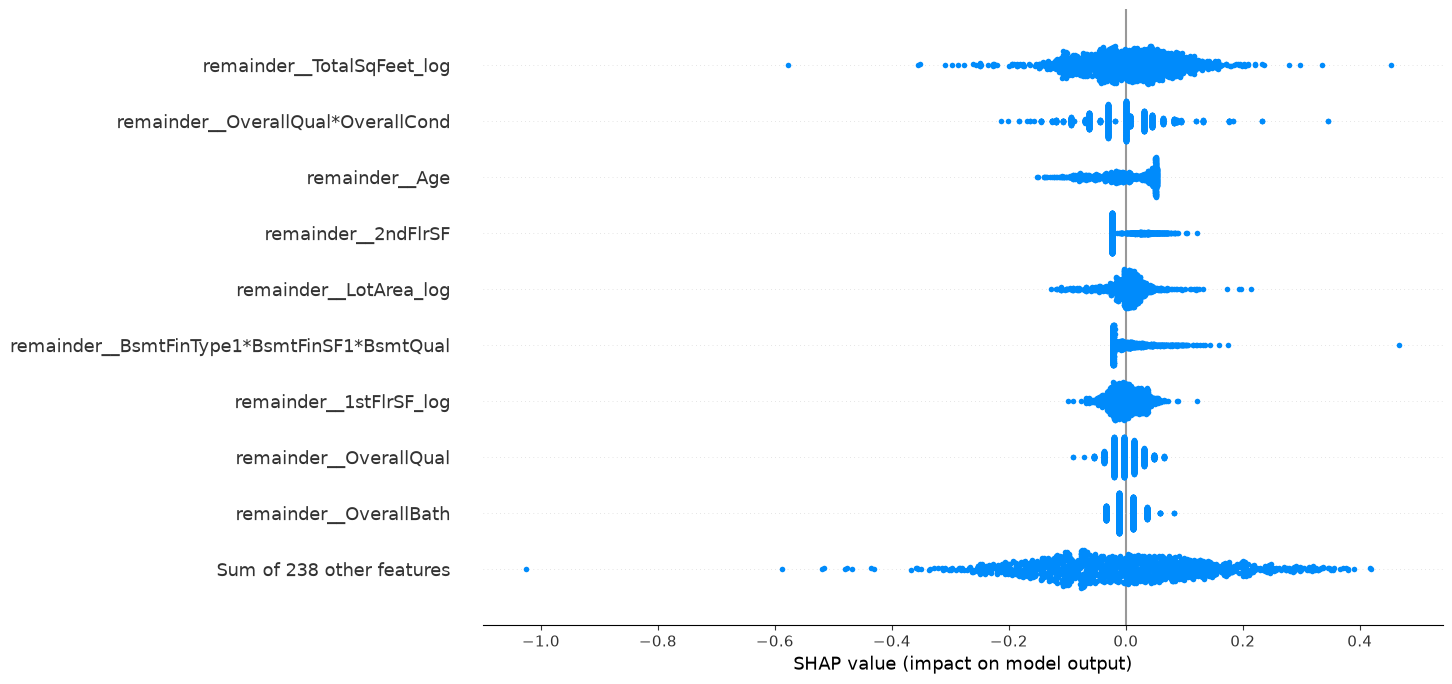

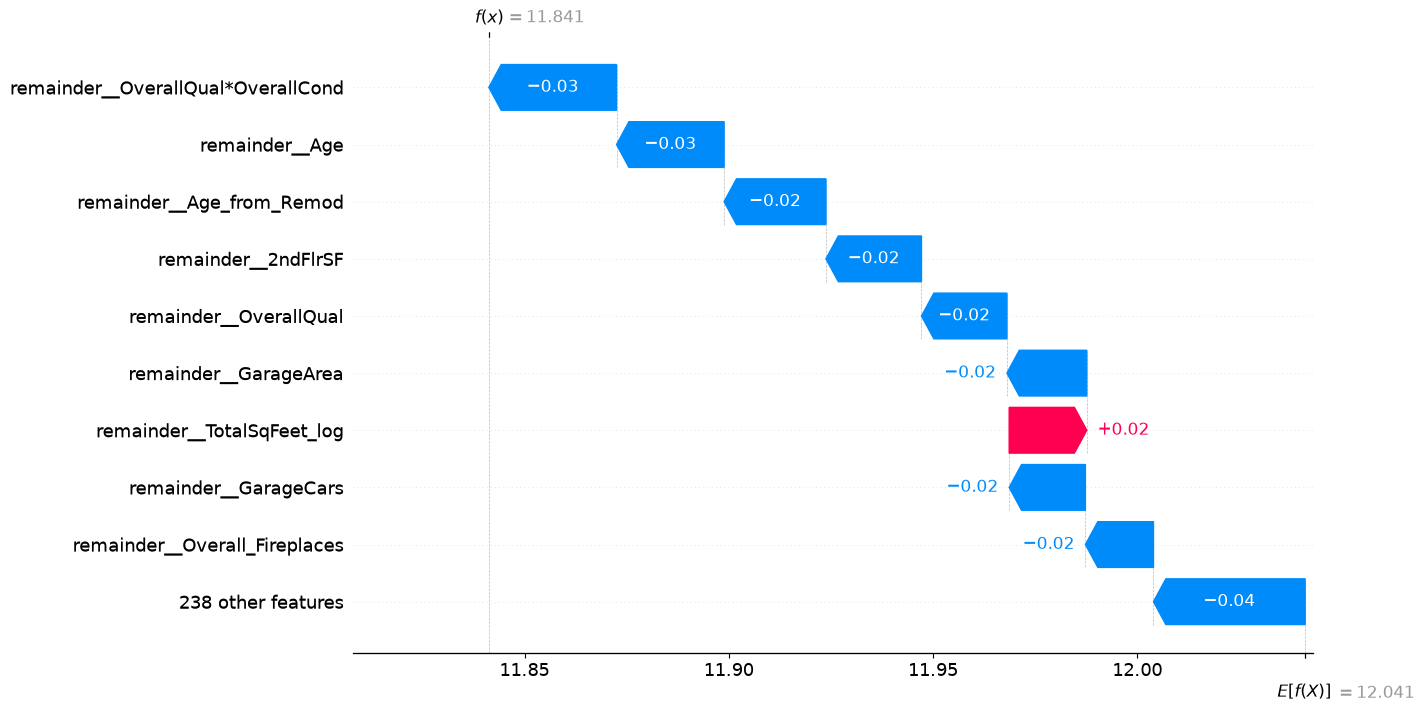

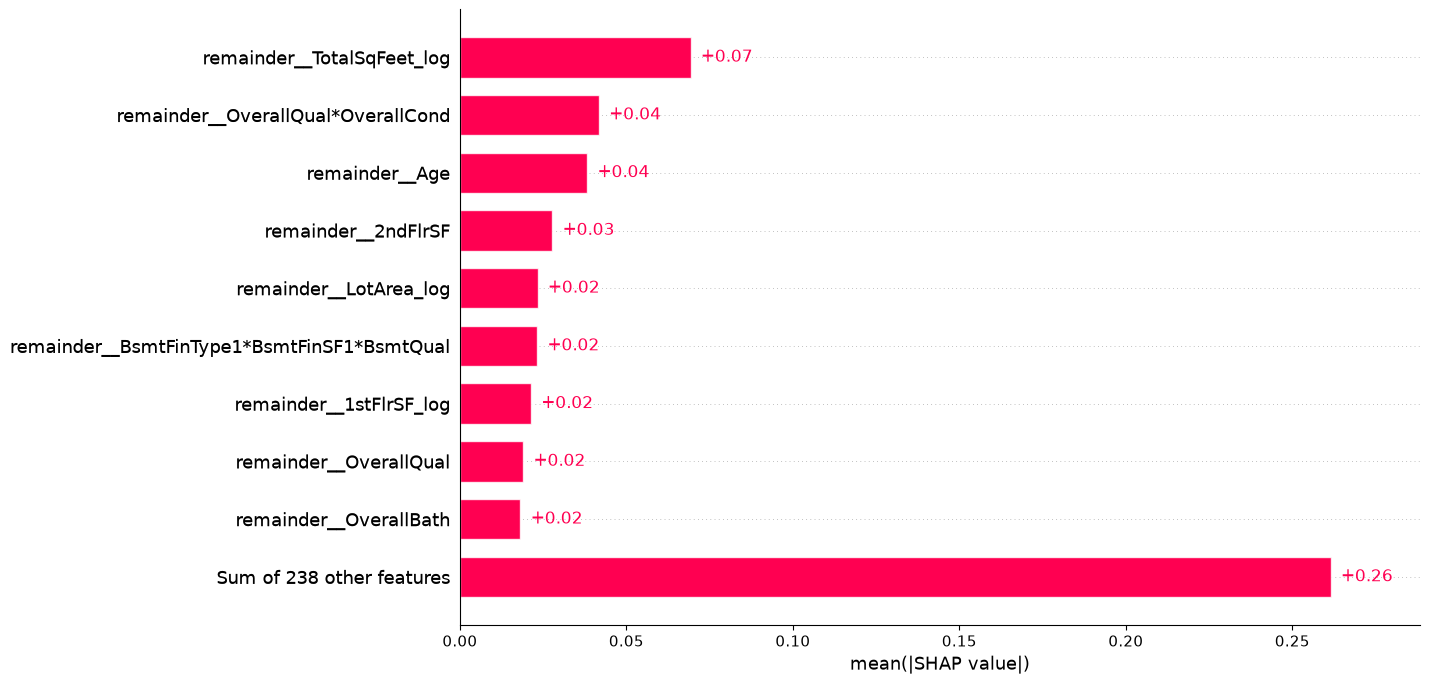

In [146]:
#One param
param_plot = plot_drawer.draw_parameter(
        result,
        parameter='model__alpha',
        fixed_params=best_param,
        run_id = lasso_run_id
        ) 
plt.show(param_plot)
#Heatmap
heatmap = plot_drawer.draw_heatmap(
        result,
        parameter_x = 'model__max_iter', parameter_y='model__alpha',
        fixed_params=best_param,
        run_id=lasso_run_id)
plt.show(heatmap)
#Shap_plots
shap_plots = plot_drawer.create_shap_plots(best_Lasso,'linear',X_train,lasso_run_id)
for fig in shap_plots:
    display(fig)

In [147]:
mlflow.end_run()

## Other models

In [148]:
model_configs = {
    "ridge": {
        "pipeline": Pipeline([
            ("feature_tranform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", Ridge()),
        ]),
        "parameters": {
            "model__alpha": np.linspace(150, 1000, 50),  # np.linspace(0.001, 20, 20)
            "model__solver": ["saga"],
            "model__max_iter": [1000],
            "model__random_state": [SEED],
        },
        'fit_param': {},
        "n_iter": 250,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        'shap_mode':'linear'
    },

    # # "knn": {
    # #     "pipeline": Pipeline([
    # #         ("feature_tranform", FeatureTransformer()),
    # #         ("encoder", clone(encoder_transformer)),
    # #         ("scaler", StandardScaler()),
    # #         ("model", KNeighborsRegressor()),
    # #     ]),
    # #     "parameters": {
    # #         "model__n_neighbors": np.linspace(4, 30, 15, dtype=int),
    # #         "model__weights": ["uniform", "distance"],
    # #         "model__p": [1, 2],
    # #         "model__n_jobs": [-1],
    # #     },
    # #     'fit_param': {},
    # #     "n_iter": 250,
    # #     "plot_param": "model__n_neighbors",
    # #     "heatmap_params": ("model__n_neighbors", "model__p"),
    # #     'shap_mode':'-'
    # # },

    "decision_tree": {
        "pipeline": Pipeline([
            ("feature_tranform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", DecisionTreeRegressor()),
        ]),
        "parameters": {
            "model__max_depth": [6],
            "model__criterion": ["squared_error"],
            "model__splitter": ["best"],
            "model__min_samples_split": [36],
            "model__min_samples_leaf": [11],
            "model__max_leaf_nodes": [50],
            "model__min_impurity_decrease": [0],
            "model__random_state": [SEED],
        },
        'fit_param': {},
        "n_iter": 250,
        "plot_param": "model__max_depth",
        "heatmap_params": ("model__max_depth", "model__min_samples_leaf"),
        'shap_mode':'tree'
    },

    "random_forest": {
        "pipeline": Pipeline([
            ("feature_tranform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", RandomForestRegressor()),
        ]),
        "parameters": {
            # bootstrap=True
            "model__n_estimators": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__max_depth": [13],  # np.linspace(1, 10, 5, dtype=int)
            "model__criterion": ["squared_error"],
            "model__n_jobs": [-1],
            "model__min_samples_split": [10],  # np.linspace(10, 100, 5, dtype=int)
            "model__min_samples_leaf": [5],  # np.linspace(5, 15, 5, dtype=int); min_samples_leaf: np.int64(6)
            "model__max_leaf_nodes": [75],  # np.linspace(50, 70, 5, dtype=int)
            "model__min_impurity_decrease": [0],
            "model__max_features": [None],  # "sqrt", "log2"
            "model__bootstrap": [True],
            "model__max_samples": [0.8],
            "model__oob_score": [True, False],
            "model__random_state": [SEED],
        },
        'fit_param': {},
        "n_iter": 250,
        "plot_param": "model__n_estimators",
        "heatmap_params": ("model__n_estimators", "model__max_depth"),
        'shap_mode':'tree'
    },

    "xgboost": {
        "pipeline": Pipeline([
            ("feature_tranform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", XGBRegressor()),
        ]),
        "parameters": {
            "model__device": ["cuda"],
            "model__booster": ["gbtree"],
            "model__tree_method": ["hist"],
            "model__n_estimators": [1000],  # np.linspace(1, 100, 5, dtype=int); лучшее 12
            "model__learning_rate": [np.float64(0.013000000000000001)],  # [np.float64(0.0775)]
            "model__max_depth": [6],  # [6, 8, 10, 12, 14]; лучшее 10 для случайного леса
            "model__min_child_weight": [5],  # np.linspace(1, 10, 5, dtype=int)
            "model__n_jobs": [-1],
            "model__subsample": [0.5],  # [0.6, 0.8, 1.0]
            "model__colsample_bytree": [0.4793103448275863],  # [0.65, 0.7, 0.75]
            "model__reg_alpha": [0.003666666666666667],  # [0, 0.01, 0.1, 1]
            "model__reg_lambda": [0.04555555555555556],  # [0.01, 0.1, 0.5, 5, 10]
            "model__gamma": [0],  # np.linspace(0.01, 0.1, 10)
            "model__objective": ["reg:squarederror"],
            "model__eval_metric": ["rmse"],  # RMSE для регрессии
            "model__random_state": [SEED],
        },
        'fit_param': {},
        "n_iter": 250,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__n_estimators"),
        'shap_mode':'tree'
    },

    "lightgbm": {
        "pipeline": Pipeline([
            ("feature_tranform", FeatureTransformer(cat_boosting=True)),
            ("model", LGBMRegressor()),
        ]),
        "parameters": {
            "model__device": ["cpu"],
            "model__boosting_type": ["gbdt"],
            "model__n_estimators": [200],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [0.098],  # np.linspace(0.01, 0.1, 5); [np.float64(0.0775)]
            "model__max_depth": [4],  # [4, 5, 6, 8]
            "model__subsample": [0.4],  # [0.6, 0.8, 1.0]
            "model__colsample_bytree": [0.8],  # [0.6, 0.8, 1.0]
            "model__reg_alpha": [0.008],  # [0.1, 0.2, 0.4, 0.5, 1]
            "model__reg_lambda": [0.04000000000000001],  # [0.01, 0.1, 0.5, 5, 10]
            "model__objective": ["regression"],
            "model__metric": ["rmse"],
            "model__min_child_samples": [40],
            "model__min_child_weight": [1],  # np.linspace(1, 5, 3, dtype=int)
            "model__min_split_gain": [0.0005],  # np.linspace(0.01, 0.1, 5)
            "model__n_jobs": [-1],
            "model__random_state": [SEED],
        },
        "fit_param" : {},
        "n_iter": 250,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__max_depth"),
        'shap_mode':'lightgbm'
    },

    "catboost": {
        "pipeline": Pipeline([
            ("feature_tranform", FeatureTransformer(cat_boosting=True)),
            ("model", CatBoostRegressor(allow_writing_files=False)),
        ]),
        "parameters": {
            "model__boosting_type": ["Plain"],  # ["Plain", "Ordered"]
            "model__iterations": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [np.float64(0.08)],  # [0.08]
            "model__depth": [6],  # [4, 5, 6, 8]
            "model__bootstrap_type": ["Bernoulli"],
            "model__thread_count": [-1],
            "model__l2_leaf_reg": [np.float64(0.0098)],  # np.float64(0.0098)
            "model__rsm": [0.8],  # [0.6, 0.8, 1.0]
            "model__subsample": [1.0],
            "model__border_count": [32],
            "model__min_data_in_leaf": [45],
            "model__max_ctr_complexity": [2],
            "model__one_hot_max_size": [5],
            "model__eval_metric": ["RMSE"],
            "model__loss_function": ["RMSE"],
            "model__random_strength": [1],  # [0, 0.5, 1, 2]
            "model__verbose": [False],
            "model__random_seed": [SEED],
        },
        'fit_param': {"model__cat_features": FeatureTransformer.cat_cols},
        "n_iter": 250,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
        'shap_mode':'catboost'
    },
}

In [149]:
def evaluate_models(model_configs,skf,X_train,y_train):
    id_dict = {}
    results = []
    for key, item in model_configs.items():
        best_model,best_param,best_scor,oof_rmse,result,run_id,model_ids  =  search_params(X_train,y_train,skf,item["pipeline"],item['parameters'],item["fit_param"],item["n_iter"])
        print(
            "---------------------------------\n"
            f"{key}\n"
            f"Лучшие параметры: {best_param}\n"
            f"CV RMSE: {-best_scor:.5f}\n"
            f"OOF RMSE: {oof_rmse:.5f}"
            "---------------------------------\n")
        results.append({'model': key, 'CV_RMSE':f"{-best_scor:.5f}",'OOF_RMSE': f"{oof_rmse:.5f}"})

        #One param
        param_plot = plot_drawer.draw_parameter(
            result,
            parameter=item['plot_param'],
            fixed_params=best_param,
            run_id = run_id) 
        # plt.show(param_plot)
        #Heatmap
        heatmap = plot_drawer.draw_heatmap(
                result,
                parameter_x = item['heatmap_params'][0], parameter_y=item['heatmap_params'][1],
                fixed_params=best_param,
                run_id=run_id)
        # plt.show(heatmap)
        #Shap_plots
        shap_plots = plot_drawer.create_shap_plots(best_model,item['shap_mode'],X_train,run_id)
        # for fig in shap_plots:
        #     display(fig)
        id_dict[key] = model_ids

    with open("models_id.json", "w", encoding="utf-8") as file:
        json.dump(id_dict, file)
        
    resutls_df = pd.DataFrame(results)

    return resutls_df

In [150]:
cv_result = evaluate_models(model_configs,skf,X_train,y_train)
cv_result

RandomizedSearchCV:   0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 50 is smaller than n_iter=250. Running 50 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 50 candidates, totalling 250 fits


2026/10/26 16:04:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/26 16:04:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/26 16:04:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mec

...

  0%|          | 0/5 [00:00<?, ?it/s]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 1 is smaller than n_iter=250. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
2026/10/26 16:44:13 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/26 16:44:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alterna

🏃 View run CatBoostRegressor at: http://127.0.0.1:5000/#/experiments/1/runs/0dfb51b5ddf944aa9bdd29142273ec98
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
---------------------------------
catboost
Лучшие параметры: {'model__verbose': False, 'model__thread_count': -1, 'model__subsample': 1.0, 'model__rsm': 0.8, 'model__random_strength': 1, 'model__random_seed': 42, 'model__one_hot_max_size': 5, 'model__min_data_in_leaf': 45, 'model__max_ctr_complexity': 2, 'model__loss_function': 'RMSE', 'model__learning_rate': np.float64(0.08), 'model__l2_leaf_reg': np.float64(0.0098), 'model__iterations': 1000, 'model__eval_metric': 'RMSE', 'model__depth': 6, 'model__border_count': 32, 'model__bootstrap_type': 'Bernoulli', 'model__boosting_type': 'Plain'}
CV RMSE: 0.12038
OOF RMSE: 0.12094---------------------------------

🏃 View run CatBoostRegressor at: http://127.0.0.1:5000/#/experiments/1/runs/0dfb51b5ddf944aa9bdd29142273ec98
🧪 View experiment at: http://127.0.0.1:5000/#/experiments

,model,CV_RMSE,OOF_RMSE
0,ridge,0.13472,0.13779
1,decision_tree,0.18581,0.18615
2,random_forest,0.14330,0.14421
3,xgboost,0.12112,0.12226
4,lightgbm,0.12392,0.12494
5,catboost,0.12038,0.12094


In [151]:
def load_pipelines(path="models_id.json"):
    # Ожидаемый формат:
    # {
    #     "ridge": ["models:/m-...", "models:/m-..."],
    #     "catboost": ["models:/m-...", "models:/m-..."]
    # }
    with open(path, encoding="utf-8") as file:
        model_ids = json.load(file)

    pipelines = {}

    for model_name, model_uris in model_ids.items():
        pipelines[model_name] = [
            mlflow.sklearn.load_model(
                uri if ":/" in uri else f"models:/{uri}"
            )
            for uri in model_uris
        ]

        print(f"{model_name}: загружено {len(pipelines[model_name])} пайплайнов")

    return pipelines

def run_test(pipelines, X_holdout, y_holdout):
    scores = {}

    for model_name, fold_pipelines in pipelines.items():
        pred_log = np.mean(
            [pipeline.predict(X_holdout) for pipeline in fold_pipelines],
            axis=0,
        ).reshape(-1)

        rmse = np.sqrt(
            np.mean((np.asarray(y_holdout).reshape(-1) - pred_log) ** 2)
        )
        scores[model_name] = rmse

    results = (
        pd.DataFrame(scores.items(), columns=["model", "holdout_log_rmse"])
        .sort_values("holdout_log_rmse")
        .reset_index(drop=True)
    )

    print(results.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
    return results


# Предсказания на Kaggle test и отдельный CSV для каждой модели
def run_inference(pipelines, data_test, output_dir="submissions"):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    predictions = {}

    for model_name, fold_pipelines in pipelines.items():
        pred_log = np.mean(
            [pipeline.predict(data_test) for pipeline in fold_pipelines],
            axis=0,
        ).reshape(-1)

        pred_price = np.expm1(pred_log)
        predictions[model_name] = pred_price

        submission = pd.DataFrame({
            "Id": data_test["Id"].to_numpy(),
            "SalePrice": pred_price,
        })

        path = output_dir / f"submission_{model_name}.csv"
        submission.to_csv(path, index=False)

        print(f"{model_name}: {len(submission)} строк → {path}")

    return predictions

In [152]:
# Запуск
output_dir = r'C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\data\submission'
pipelines = load_pipelines("models_id.json")
test_results = run_test(pipelines, X_holdout, y_holdout)
preds = run_inference(pipelines, data_test,output_dir)

ridge: загружено 5 пайплайнов


decision_tree: загружено 5 пайплайнов


random_forest: загружено 5 пайплайнов


xgboost: загружено 5 пайплайнов


lightgbm: загружено 5 пайплайнов


catboost: загружено 5 пайплайнов
        model  holdout_log_rmse
        ridge           0.12559
     catboost           0.12899
      xgboost           0.13361
     lightgbm           0.13506
random_forest           0.15127
decision_tree           0.17510
ridge: 1459 строк → C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\data\submission\submission_ridge.csv
decision_tree: 1459 строк → C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\data\submission\submission_decision_tree.csv
random_forest: 1459 строк → C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\data\submission\submission_random_forest.csv
xgboost: 1459 строк → C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\data\submission\submission_xgboost.csv
lightgbm: 1459 строк → C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\data\submis